# 🎨 Text-to-Image Generation with CLIP + VQGAN

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Abdullah87146/image-generation-clip-vqgan/blob/main/image_generation_clip_vqgan.ipynb)

This notebook generates images from a text prompt, for example *"An alien planet with strange vegetation and creatures"*.

### How it works (in simple words)
| Part | Role | What it does |
|---|---|---|
| **VQGAN** | the "painter" | turns a list of numbers (called a *latent*) into an image |
| **CLIP** | the "judge" | measures how well an image matches a text description |

We start with **random numbers**, so the first image is just noise. Then we repeat this many times:
1. VQGAN paints an image from the numbers
2. CLIP checks how well the image matches the prompt
3. We slightly change the numbers to get a better match

After a few hundred repeats, the image looks like the prompt.

### Before you run
This notebook needs a **GPU**. In Google Colab: `Runtime` → `Change runtime type` → choose a **GPU** → then `Runtime` → `Run all`.

## 1. Install the libraries and download the code
- `pip install` installs the extra Python libraries we need
- `git clone` downloads the code of CLIP and VQGAN (called *taming-transformers*) from GitHub

In [1]:
!pip install -q ftfy regex tqdm omegaconf einops pytorch-lightning
!git clone -q https://github.com/openai/CLIP.git
!git clone -q https://github.com/CompVis/taming-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.1 MB/s eta 0:00:00


## 2. Import the libraries
We also check that a GPU is available. Without a GPU this notebook is far too slow.

In [2]:
import os, sys, types, importlib
import torch
import torchvision
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

# Tell Python where the VQGAN code is
sys.path.append("taming-transformers")


def instantiate_from_config(config):
    module_name, class_name = config["target"].rsplit(".", 1)
    the_class = getattr(importlib.import_module(module_name), class_name)
    return the_class(**config.get("params", {}))

fake_main = types.ModuleType("main")
fake_main.instantiate_from_config = instantiate_from_config
sys.modules["main"] = fake_main

from CLIP import clip                    # the CLIP model (the judge)
from taming.models.vqgan import VQModel  # the VQGAN model (the painter)

# Use the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
assert device.type == "cuda", "No GPU found. Use Runtime -> Change runtime type -> GPU, then run again."

Using device: cuda


## 3. Settings
This is the only cell you need to change to experiment.

| Setting | Meaning |
|---|---|
| `include` | What you want to see. One image is generated for each prompt in the list. |
| `exclude` | What the image should **not** look like. |
| `extras` | Extra style words that are added to every prompt. |
| `total_steps` | How many times we repeat the improve-the-image loop (more = slower, usually better). |
| `learning_rate` | How big each change is. Too big = messy image, too small = very slow progress. |
| `noise_factor` | How much random noise is added to the image crops (helps the result look less rigid). |

*Note: do not leave `exclude` or `extras` empty. Write at least one word.*

In [3]:
include = [
    "An alien planet with strange vegetation and creatures",
    "A castle on a cliff at sunset, fantasy painting",
    "A futuristic city at night with neon lights",
]
exclude = "realistic"
extras = "surreal, colorful"

total_steps = 200        # how many improvement steps per image
preview_every = 50       # show a preview image every 50 steps
learning_rate = 0.5
weight_decay = 0.1       # keeps the numbers small, which helps the painter
noise_factor = 0.22
w1 = 1                   # weight of the main prompt
w2 = 1                   # weight of the extra style words

image_size = 450         # image height and width in pixels

## 4. Load the CLIP model (the judge)
`ViT-B/32` is the name of the CLIP version we use. It is downloaded automatically.

In [4]:
clipmodel, _ = clip.load("ViT-B/32", jit=False)
clipmodel.eval()   # evaluation mode: we only use CLIP, we do not train it
print("CLIP loaded")

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 126MiB/s]


CLIP loaded


## 5. Load the VQGAN model (the painter)
We download two files: the trained model (`last.ckpt`) and its settings (`model.yaml`). This can take a minute.

In [5]:
!mkdir -p models/vqgan_imagenet_f16_16384/checkpoints
!mkdir -p models/vqgan_imagenet_f16_16384/configs

# Download only if the model is not there yet
if len(os.listdir("models/vqgan_imagenet_f16_16384/checkpoints/")) == 0:
    !wget -q 'https://heibox.uni-heidelberg.de/f/867b05fc8c4841768640/?dl=1' -O 'models/vqgan_imagenet_f16_16384/checkpoints/last.ckpt'
    !wget -q 'https://heibox.uni-heidelberg.de/f/274fb24ed38341bfa753/?dl=1' -O 'models/vqgan_imagenet_f16_16384/configs/model.yaml'

In [6]:
# Read the model settings
config = OmegaConf.load("models/vqgan_imagenet_f16_16384/configs/model.yaml")

# We only generate images (no training), so the training loss is not needed
config.model.params.lossconfig.target = "torch.nn.Identity"

# Build the model and load the trained weights
vqgan = VQModel(**config.model.params)
checkpoint = torch.load("models/vqgan_imagenet_f16_16384/checkpoints/last.ckpt",
                        map_location="cpu", weights_only=False)
vqgan.load_state_dict(checkpoint["state_dict"], strict=False)
vqgan = vqgan.eval().to(device)
print("VQGAN loaded")

Working with z of shape (1, 256, 16, 16) = 65536 dimensions.
VQGAN loaded


## 6. Helper functions
Small functions that we use again and again.

In [7]:
def generate_image(latent):
    # Turn the latent numbers into an image (this is the VQGAN "painter")
    x = vqgan.post_quant_conv(latent)
    return vqgan.decoder(x)

def to_range_0_1(image):
    # The VQGAN output has values between -1 and 1. We convert them to 0-1 so they are valid pixel values.
    return (image.clip(-1, 1) + 1) / 2

def show_image(image):
    # Show an image tensor (3 x height x width, values between 0 and 1)
    image = image.mul(255).byte().cpu().numpy().transpose((1, 2, 0))
    plt.figure(figsize=(6, 6))
    plt.axis("off")
    plt.imshow(image)
    plt.show()

def get_current_image(latent):
    # Paint the image from the current numbers (no learning happens here)
    with torch.no_grad():
        image = generate_image(latent)
    return to_range_0_1(image.cpu())[0]

## 7. The numbers we improve (the latent)
The image is created from a block of numbers called the **latent**. At the start these numbers are random. The optimizer (`AdamW`) changes them step by step so the image matches the prompt better.

In [8]:
def make_latent():
    # Random start numbers with shape: 1 x 256 x 28 x 28  (28 = 450 // 16)
    numbers = 0.5 * torch.randn(1, 256, image_size // 16, image_size // 16).to(device)
    latent = torch.nn.Parameter(torch.sin(numbers))   # Parameter = "numbers the optimizer may change"
    optimizer = torch.optim.AdamW([latent], lr=learning_rate, weight_decay=weight_decay)
    return latent, optimizer

## 8. Turn the text prompts into numbers
CLIP converts text into a list of 512 numbers (an *embedding*). Texts with a similar meaning get similar numbers.

In [9]:
def encode_text(text):
    tokens = clip.tokenize(text).to(device)
    return clipmodel.encode_text(tokens).detach().clone()

include_enc = [encode_text(text) for text in include]   # one embedding per prompt
exclude_enc = encode_text(exclude)
extras_enc = encode_text(extras)
print("Encoded", len(include_enc), "prompt(s)")

Encoded 3 prompt(s)


## 9. Random crops
CLIP is shown many small, randomly cut and slightly changed pieces (*crops*) of the image instead of the whole image. This makes the result more stable and gives the image more detail. We also add a little random noise.

In [10]:
# CLIP expects pixel values normalized like this
normalize = torchvision.transforms.Normalize((0.48145466, 0.4578275, 0.40821073),
                                             (0.26862954, 0.26130258, 0.27577711))

# Random flip and small rotation / shift
random_changes = torch.nn.Sequential(
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomAffine(30, (0.2, 0.2), fill=0)
).to(device)

def make_crops(image, num_crops=32):
    # Add a black border around the image, then randomly flip / rotate it
    border = image_size // 2
    image = torch.nn.functional.pad(image, (border, border, border, border), mode="constant", value=0)
    image = random_changes(image)

    crops = []
    for _ in range(num_crops):
        # Pick a random crop size and a random position
        crop_size = int(torch.normal(1.2, 0.3, ()).clip(0.43, 1.9) * image_size)
        x = torch.randint(0, int(image_size * 2 - crop_size), ())
        y = torch.randint(0, int(image_size * 2 - crop_size), ())
        crop = image[:, :, x:x + crop_size, y:y + crop_size]

        # CLIP needs 224 x 224 pixel images
        crop = torch.nn.functional.interpolate(crop, (224, 224), mode="bilinear", align_corners=True)
        crops.append(crop)

    crops = torch.cat(crops, 0)   # shape: 32 x 3 x 224 x 224

    # Add a little random noise
    noise = torch.randn_like(crops)
    noise_strength = torch.rand((crops.shape[0], 1, 1, 1)).to(device)
    return crops + noise_factor * noise_strength * noise

## 10. The loss: how bad is the image?
The **loss** is one number that tells us how far the image is from what we want. The lower the loss, the better the image.

We use *cosine similarity* (how similar two lists of numbers are, from -1 to 1):
- the image should be **similar** to the prompt + extras → we subtract this similarity (higher similarity = lower loss)
- the image should be **different** from the `exclude` text → we add this similarity (higher similarity = higher loss)

In [11]:
def compute_loss(latent, prompt_enc):
    alpha = 1     # importance of the prompt
    beta = 0.5    # importance of the exclude text

    # 1. Paint the image and cut it into crops
    image = to_range_0_1(generate_image(latent))
    crops = normalize(make_crops(image))

    # 2. Let CLIP "look" at the crops (32 x 512 numbers)
    image_enc = clipmodel.encode_image(crops)

    # 3. Combine the prompt and the style words into one text embedding
    text_enc = w1 * prompt_enc + w2 * extras_enc
    text_enc = text_enc / text_enc.norm(dim=-1, keepdim=True)

    # 4. Compare the crops with the texts
    similar_to_prompt = torch.cosine_similarity(text_enc, image_enc, -1)
    similar_to_exclude = torch.cosine_similarity(exclude_enc, image_enc, -1)

    loss = -alpha * similar_to_prompt + beta * similar_to_exclude
    return loss.mean()

## 11. Generate the images 🚀
For every prompt we repeat the same 4 steps `total_steps` times:
1. compute the loss
2. clear the old gradients (`zero_grad`)
3. work out how to improve the numbers (`backward`)
4. change the numbers a little (`step`)

A preview is shown every `preview_every` steps, and the final image is saved in the `results/` folder.

=== Image 1 of 3: An alien planet with strange vegetation and creatures ===
step: 50 | loss: -0.2156


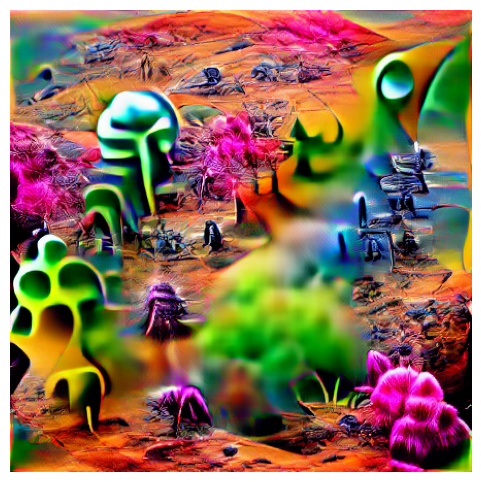

step: 100 | loss: -0.2284


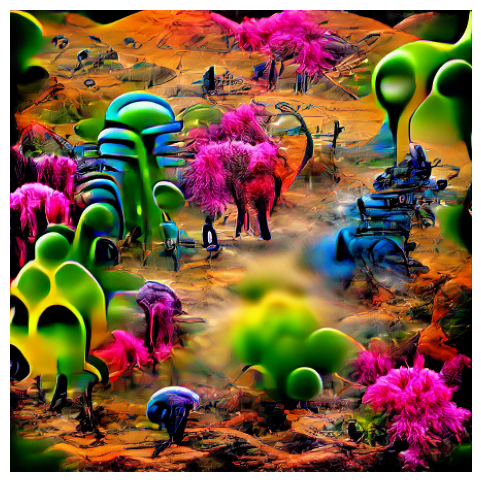

step: 150 | loss: -0.2296


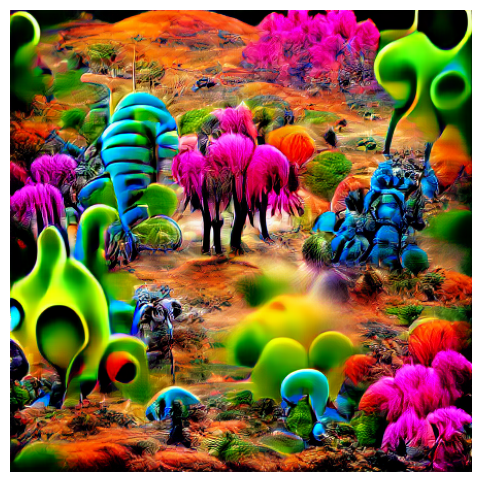

Final result:


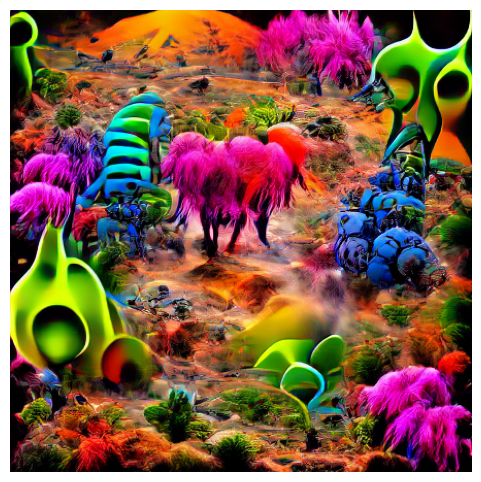

=== Image 2 of 3: A castle on a cliff at sunset, fantasy painting ===
step: 50 | loss: -0.2607


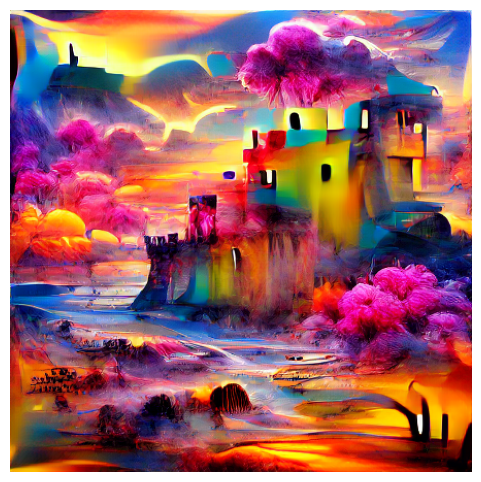

step: 100 | loss: -0.2717


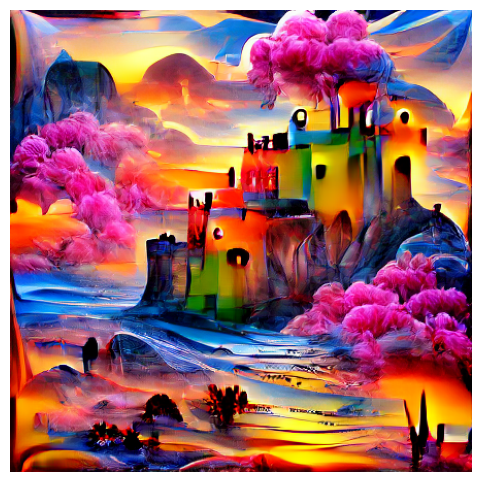

step: 150 | loss: -0.2769


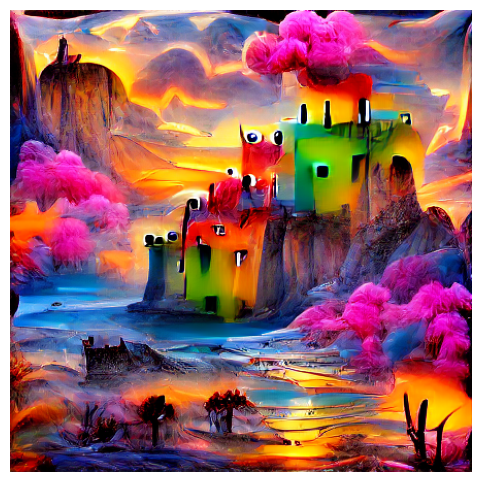

Final result:


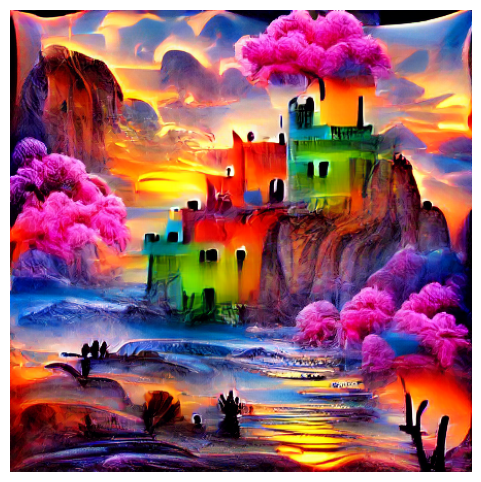

=== Image 3 of 3: A futuristic city at night with neon lights ===
step: 50 | loss: -0.2281


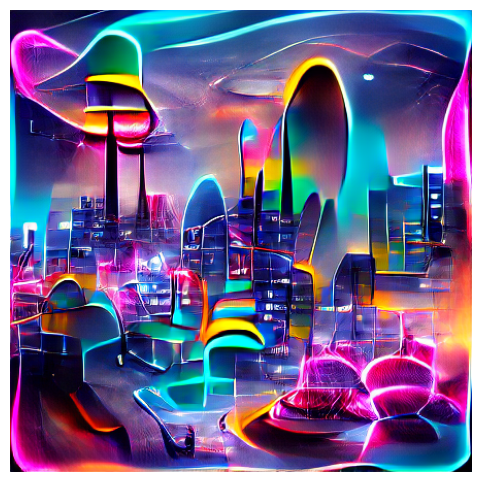

step: 100 | loss: -0.2288


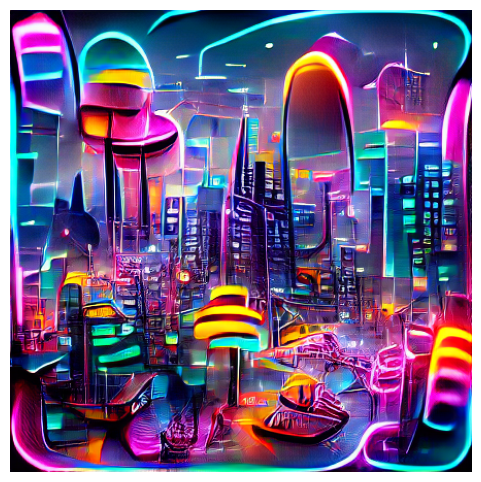

step: 150 | loss: -0.2563


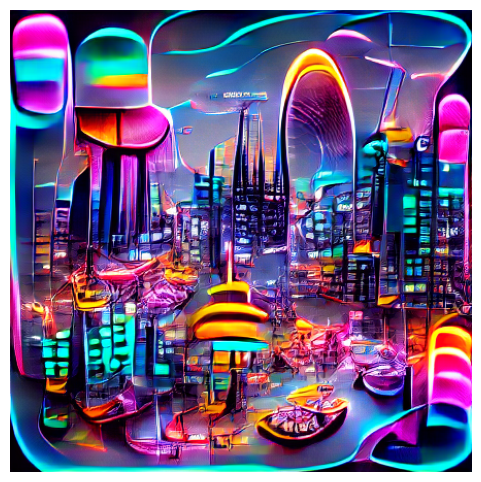

Final result:


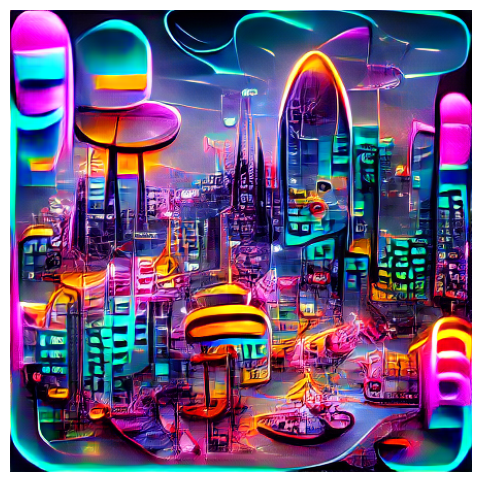

Done! The images are saved in the 'results' folder.


In [12]:
os.makedirs("results", exist_ok=True)
final_images = []

for i, prompt_enc in enumerate(include_enc):
    print(f"=== Image {i + 1} of {len(include_enc)}: {include[i]} ===")
    latent, optimizer = make_latent()

    for step in range(total_steps):
        loss = compute_loss(latent, prompt_enc)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Show a preview from time to time
        if step > 0 and step % preview_every == 0:
            print("step:", step, "| loss:", round(loss.item(), 4))
            show_image(get_current_image(latent))

    # Final image: show it and save it as a PNG file
    print("Final result:")
    final_image = get_current_image(latent)
    show_image(final_image)
    torchvision.utils.save_image(final_image, f"results/result_{i + 1}.png")
    final_images.append(final_image)

    torch.cuda.empty_cache()   # free GPU memory before the next prompt

print("Done! The images are saved in the 'results' folder.")

## 12. All results together

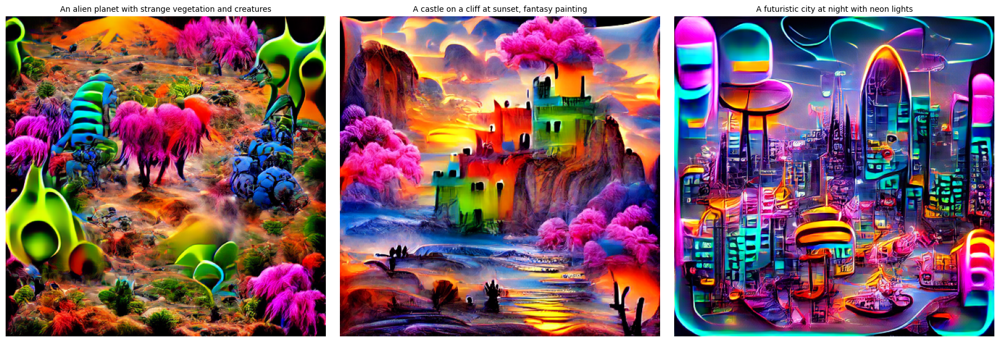

In [13]:
fig, axes = plt.subplots(1, len(final_images), figsize=(6 * len(final_images), 6))
if len(final_images) == 1:
    axes = [axes]

for ax, image, prompt in zip(axes, final_images, include):
    ax.imshow(image.mul(255).byte().numpy().transpose((1, 2, 0)))
    ax.set_title(prompt, fontsize=10, wrap=True)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Notes
- The images look abstract and painting-like. This method *optimizes* an image to match the text; it is not a modern text-to-image model such as Stable Diffusion.
- Every run gives different images because the starting numbers are random.
- Try your own prompts in the **Settings** cell (section 3).

**Models used:** [CLIP](https://github.com/openai/CLIP) (OpenAI) and [VQGAN](https://github.com/CompVis/taming-transformers) (Esser, Rombach and Ommer, *Taming Transformers for High-Resolution Image Synthesis*, 2021).